# Defining a categorical scoring system

This notebook explores how we translate a continuous system of risk values into an 11-step categorical scoring system.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [2]:
duckdb.sql("""INSTALL SPATIAL; LOAD SPATIAL; INSTALL HTTPFS; LOAD HTTPFS; INSTALL AWS; LOAD AWS""")
duckdb.sql("""CREATE SECRET (TYPE s3, PROVIDER credential_chain, REGION 'us-west-2')""")

SuccessBOOLEAN
True


In [3]:
%%time

version = '2.0.0'

dataset_uri = f's3://carbonplan-ocr/output/fire/v{version}/vector/buildings.geoparquet'

# ~28K buildings have NaN risk; np.percentile and stats.percentileofscore return NaN if any are kept.
df = (
    duckdb.sql(f"""
SELECT rps_2011, rps_2047
FROM read_parquet('{dataset_uri}')
""")
    .df()
    .dropna()
)

df.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 3.59 s, sys: 1.12 s, total: 4.71 s
Wall time: 5.15 s


,rps_2011,rps_2047
0,0.001091,0.001403
1,0.004855,0.005018
2,0.002033,0.002428
3,0.001505,0.001506
4,0.000778,0.000936


The distribution of risk values in this dataset is skewed with a very long tail at higher levels of risk. This skewed distribution can make it hard to distinguish both differences among risk levels at both higher and lower levels of risk. We overcome this, we design a scoring system with bins whose relative prevalence of buildings descend monotonically with increasing risk scores. We design the bins like this so that we can distinguish among risk values across the highly heterogeneous domain where risk values span multiple orders of magnitude.

Our approach is inspired by the WRC's increasingly fine percentile increments at higher levels of risk, as described in the supplemental materials for the Wildfire Risk to Communities project, specifically the `WRC_V2_DataPercentiles.xlsx` file found [here](https://www.fs.usda.gov/rds/archive/catalog/RDS-2020-0016-2). The WRC project uses "class breakpoints at 40th, 70th, 90th, and 95th percentile."  According to their documentation, that translates to breakpoints at the following values of RPS: `0.0188485, 0.0940430, 0.4081965, 0.7222983`. However, they based their percentiles and breakpoints on pixels as opposed to buildings, so they are inappropriate for us to use out-of-the-box. Given our focus on buildings, we will design our bins according to the distribution of risk values for buildings. 


We began with drafting a set of round number percentile scale breakpoints which grow increasingly close together as they near 100: `[75, 83, 88, 93, 96, 98, 99, 99.9, 99.99]`. 

In [4]:
percentiles = np.array([75, 82.5, 88, 92.5, 96, 98, 99.5, 99.9, 99.99])

We then calculate the RPS value for each of these percentiles.

In [5]:
bins = np.percentile(df[['rps_2011']].values, percentiles)

In [6]:
bins = np.insert(bins, 0, 0, axis=0)
bins = np.insert(
    bins, 1, 1e-64
)  # insert a very small non-zero number to differentiate the smallest bin by zero and non-zero
bins = np.insert(bins, 11, 100, axis=0)

All of this is probably easier shown than explained. When we use the bins calculated above to assign risk scores to the buildings in our dataset, the distribution of risk scores looks like below:

Text(0.5, 1.0, 'Counts of buildings in each score bin')

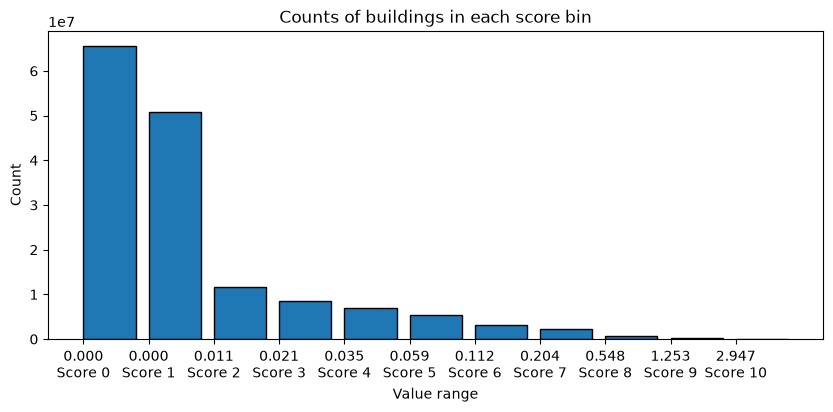

In [7]:
values = df['rps_2011'].values
counts, edges = np.histogram(values, bins=bins)
x = np.arange(len(counts))
width = 0.8
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.bar(x, counts, width=width, align='edge', edgecolor='black')
labels = [f'{bins[i]:.3f}\nScore {j}' for i, j in enumerate(range(len(bins) - 1))]
ax.set_xticks(x, labels)
ax.set_xlabel('Value range')
ax.set_ylabel('Count')
ax.set_title('Counts of buildings in each score bin')

Let's update the bin breakpoints to rounder numbers to support interpretability. Then, let's confirm that the rounding update still preserves general pattern of higher risk scores being less prevalent.

In [8]:
rounded_bins = [0.01, 0.02, 0.035, 0.06, 0.1, 0.2, 0.5, 1, 3]

We then assess the original percentiles from these rounded bins to ensure that the percentiles still decrease monotonically, with breakpoints that grow increasingly close together.

In [9]:
percentiles = stats.percentileofscore(df['rps_2011'].values, rounded_bins)
print(percentiles)

[73.92394205 81.94610265 88.05388756 92.56673127 95.48359837 97.95627309
 99.41850779 99.83346008 99.99045379]


In [10]:
bins = rounded_bins
bins = np.insert(bins, 0, 0, axis=0)
bins = np.insert(bins, 1, 1e-64, axis=0)
bins = np.insert(bins, 11, 100, axis=0)

As shown below, the bin breakpoints at higher risk levels are more spaced out (and more clustered at lower risk levels), while the corresponding percentiles are more clustered at higher risk levels and more spaced out at lower risk levels.

In [11]:
bins

array([0.0e+00, 1.0e-64, 1.0e-02, 2.0e-02, 3.5e-02, 6.0e-02, 1.0e-01,
       2.0e-01, 5.0e-01, 1.0e+00, 3.0e+00, 1.0e+02])

Text(0.5, 1.0, 'Counts of buildings in each score bin')

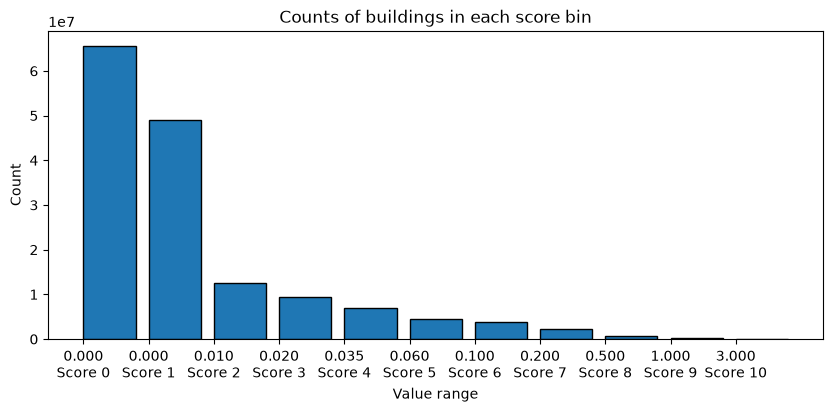

In [12]:
values = df['rps_2011'].values
counts, edges = np.histogram(values, bins=bins)
x = np.arange(len(counts))
width = 0.8
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.bar(x, counts, width=width, align='edge', edgecolor='black')
labels = [f'{bins[i]:.3f}\nScore {j}' for i, j in enumerate(range(len(bins) - 1))]
ax.set_xticks(x, labels)
ax.set_xlabel('Value range')
ax.set_ylabel('Count')
ax.set_title('Counts of buildings in each score bin')

Then let's see what the risk values look like for the future scenario:

Text(0.5, 1.0, 'Counts of buildings in each score bin')

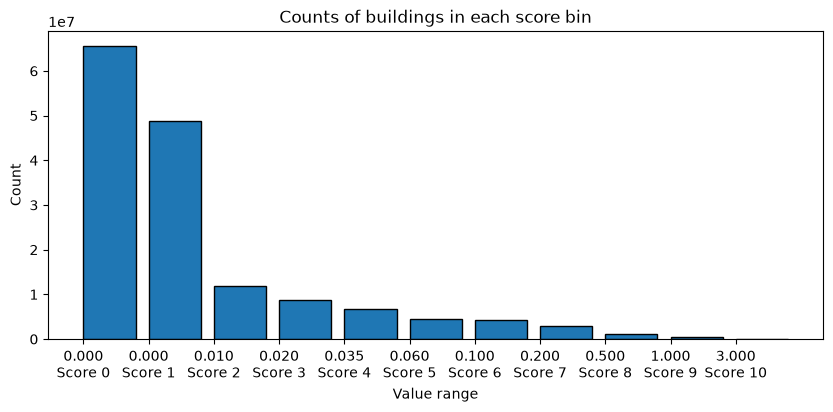

In [13]:
values = df['rps_2047'].values
counts, edges = np.histogram(values, bins=bins)
x = np.arange(len(counts))
width = 0.8
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.bar(x, counts, width=width, align='edge', edgecolor='black')
labels = [f'{bins[i]:.3f}\nScore {j}' for i, j in enumerate(range(len(bins) - 1))]
ax.set_xticks(x, labels)
ax.set_xlabel('Value range')
ax.set_ylabel('Count')
ax.set_title('Counts of buildings in each score bin')

Finally, let's compare the counts in each score bin to the previous release (v1.1.0), which used an older Overture buildings release. The bins are unchanged, so we expect only small shifts and the same monotonic shape.

In [14]:
import json

import pandas as pd

old_stats = pd.read_csv(
    'https://data.source.coop/carbonplan/carbonplan-ocr/output/fire-risk/vector/production/v1.1.0/region-analysis/nation/stats.csv',
    comment='#',
)
diff = pd.concat(
    {
        var: pd.DataFrame(
            {
                'v1.1.0': np.array(
                    json.loads(old_stats[f'risk_score_{var[4:]}_hist'][0]), dtype=int
                ),
                f'v{version}': np.histogram(df[var].values, bins=bins)[0],
            }
        )
        for var in ['rps_2011', 'rps_2047']
    },
    axis=1,
)
diff.index.name = 'score'
for var in ['rps_2011', 'rps_2047']:
    old, new = diff[var]['v1.1.0'], diff[var][f'v{version}']
    diff[var, 'change'] = new - old
    diff[var, '% change'] = (100 * (new - old) / old).round(2)
diff = diff.sort_index(axis=1, level=0, sort_remaining=False)
diff

rps_2011                             rps_2047                    \
         v1.1.0    v2.0.0  change % change    v1.1.0    v2.0.0  change   
score                                                                    
0      65916749  65635386 -281363    -0.43  65914944  65633604 -281340   
1      49227713  49096809 -130904    -0.27  48834284  48689565 -144719   
2      12472024  12450636  -21388    -0.17  11865307  11845825  -19482   
3       9466098   9479467   13369     0.14   8845448   8848461    3013   
4       7002982   7004070    1088     0.02   6706975   6713250    6275   
5       4523574   4527066    3492     0.08   4543338   4551943    8605   
6       3828504   3837666    9162     0.24   4233106   4246212   13106   
7       2261334   2269431    8097     0.36   2914160   2925566   11406   
8        641468    644020    2552     0.40   1094590   1100326    5736   
9        242565    243659    1094     0.45    559525    562000    2475   
10        14611     14816     205     1.40     85945     86274     329   

                
      % change  
score           
0        -0.43  
1        -0.30  
2        -0.16  
3         0.03  
4         0.09  
5         0.19  
6         0.31  
7         0.39  
8         0.52  
9         0.44  
10        0.38

Plotting the percent change in each score bin:

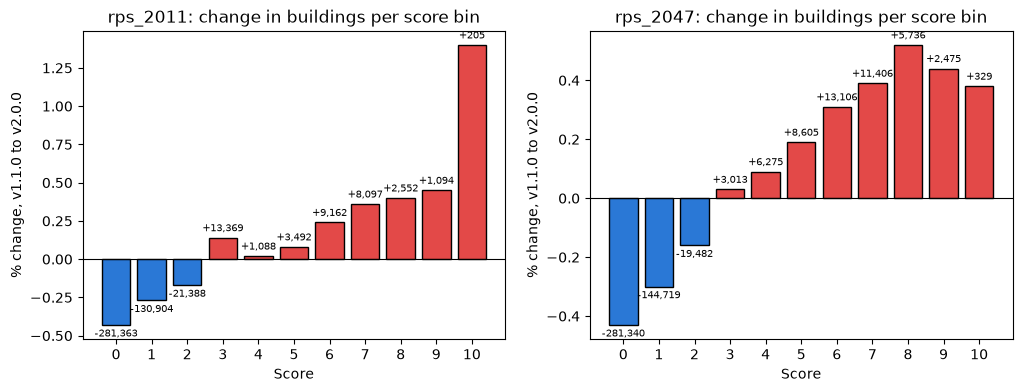

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, var in zip(axes, ['rps_2011', 'rps_2047']):
    pct = diff[var, '% change']
    ax.bar(pct.index, pct, color=np.where(pct < 0, '#2a78d6', '#e34948'), edgecolor='black')
    ax.axhline(0, color='black', lw=0.8)
    for score, (p, d) in enumerate(zip(pct, diff[var, 'change'])):
        ax.annotate(
            f'{d:+,}',
            (score, p),
            xytext=(0, 3 if p >= 0 else -3),
            textcoords='offset points',
            ha='center',
            va='bottom' if p >= 0 else 'top',
            fontsize=7,
        )
    ax.set_xticks(pct.index)
    ax.set_xlabel('Score')
    ax.set_ylabel(f'% change, v1.1.0 to v{version}')
    ax.set_title(f'{var}: change in buildings per score bin')